# Linear Elasticity

*Authors:* 
 - *Laura De Lorenzis (ETH Zürich)*
 - *Corrado Maurini (corrado.maurini@sorbonne-universite.fr)*

This notebook serves as a tutorial to solve a problem of linear elasticity using DOLFINx (FEniCS).

You can find a tutorial and useful resources for DOLFINx at the following links

- https://docs.fenicsproject.org/
- https://github.com/FEniCS/dolfinx/
- https://jorgensd.github.io/dolfinx-tutorial/, see https://jorgensd.github.io/dolfinx-tutorial/chapter2/linearelasticity.html for linear elasticity

We consider an elastic slab $\Omega$ with a straight crack $\Gamma$ subject to a mode-I loading by an applied traction force $f$, see figure. 

Using the symmetry, we will consider only half of the domain in the computation.

![title](./domain.png)

We solve the problem of linear elasticity with the finite element method, implemented using DOLFINx.

DOLFINx is advanced library that allows for efficient parallel computation. For the sake of simplicity, we assume here to work on a single processor and will not use MPI-related commands.

We start by importing the required libraries. 

In [1]:
# Import required libraries
import matplotlib.pyplot as plt
import numpy as np

import dolfinx.fem as fem
import dolfinx.mesh as mesh
import dolfinx.io as io
import dolfinx.plot as plot
import dolfinx.fem.petsc
import ufl

from mpi4py import MPI

Let us generate a mesh using gmsh (http://gmsh.info/). 
The mesh is refined around the crack tip.
The function to generate the mesh is reported in the external file `meshes.py` located in the directory `utils`.
To import it, we add `utils` to the path where the system is looking for functions to import

In [2]:
import sys
sys.path.append("../utils")
from meshes import generate_mesh_with_crack

In [3]:
Lx = 1.
Ly = 0.5
Lcrack = 0.3
lc =.05
dist_min = .1
dist_max = .3
msh, mt, ft = generate_mesh_with_crack(
        Lcrack=Lcrack,
        Lx=Lx,
        Ly=Ly,
        lc=lc,  # caracteristic length of the mesh
        refinement_ratio=10,  # how much it is refined at the tip zone
        dist_min=dist_min,  # radius of tip zone
        dist_max=dist_max,  # radius of the transition zone
        verbosity=1
    )

To plot the mesh we use `pyvista` see:
- https://jorgensd.github.io/dolfinx-tutorial/chapter3/component_bc.html
- https://docs.fenicsproject.org/dolfinx/main/python/demos/pyvista/demo_pyvista.py.html

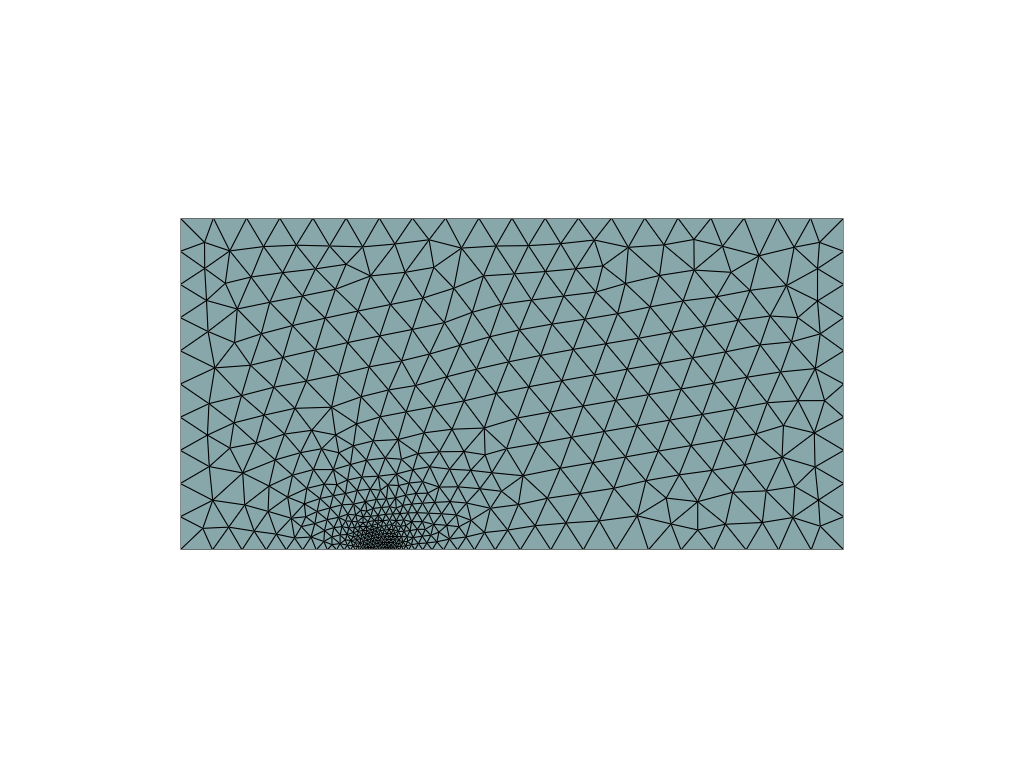

In [4]:
import pyvista
pyvista.set_jupyter_backend("static")
grid = pyvista.UnstructuredGrid(*plot.vtk_mesh(msh))
plotter = pyvista.Plotter()
plotter.add_mesh(grid, show_edges=True)
plotter.camera_position = 'xy'
if not pyvista.OFF_SCREEN:
    plotter.show()

## Finite element function space

We use here linear Lagrange triangle elements

In [5]:
V = fem.functionspace(msh, ("Lagrange", 1, (2,)))

## Dirichlet boundary conditions

We define below the functions to impose the Dirichlet boundary conditions.

In our case we want to 
- block the vertical component $u_1$ of the displacement on the part of the bottom boundary without crack
- block the horizontal component $u_0$ on the right boundary

We first get the facets to block on the boundary (`dolfinx.mesh.locate_entities_boundary`) and then the corresponding dofs (`dolfinx.fem.locate_dofs_topological`)

In [6]:
def bottom_no_crack(x):
    # the ligament ahead of the tip, the tip node included. A facet is kept
    # only when all its vertices satisfy this, so the tolerance is what puts
    # the node at x = Lcrack on the symmetry line rather than on the crack.
    return np.logical_and(np.isclose(x[1], 0.0), 
                          x[0] > Lcrack - 1e-9)

def right(x):
    return np.isclose(x[0], Lx)

right_facets = mesh.locate_entities_boundary(msh, msh.topology.dim-1, right)
right_dofs_x = fem.locate_dofs_topological(V.sub(0), msh.topology.dim-1, right_facets)
bc_right = fem.dirichletbc(np.array(0.0,dtype=np.float64), right_dofs_x, V.sub(0))

# locate the facets of the mesh that are on the bottom boundary and not on the crack
# get the corresponding dofs and define the bc object
bottom_no_crack_facets = mesh.locate_entities_boundary(msh, msh.topology.dim-1, bottom_no_crack)
bottom_no_crack_dofs_y = fem.locate_dofs_topological(V.sub(1), msh.topology.dim-1, bottom_no_crack_facets)
bc_bottom = fem.dirichletbc(0.0, bottom_no_crack_dofs_y, V.sub(1))

# collect the bcs in a list
bcs = [bc_bottom, bc_right]

## Define the bulk and surface mesures
The bulk (`dx`) and surface (`ds`) measures are used by `ufl` to write variational form with integral over the domain or the boundary, respectively. 

In this example the surface measure `ds` includes tags to specify Neumann bcs: `ds(1)` will mean the integral on the top boundary. 

In [7]:
dx = ufl.Measure("dx",domain=msh)
top_facets = mesh.locate_entities_boundary(msh, 1, lambda x : np.isclose(x[1], Ly))
top_tag = mesh.meshtags(msh, 1, top_facets, 1)
ds = ufl.Measure("ds", domain=msh, subdomain_data=top_tag)

## Define the variational problem 

We specify the problem to solve though the weak formulation written in the [ufl](https://fenics.readthedocs.io/projects/ufl/en/latest/) syntax by giving the bilinear $a(u,v)$ and linear forms $L(v)$ in 
the weak formulation: 

find the *trial function* $u$ such that for all *test function* $v$
$a(u,v)=L(v)$ with 

$$
a(u,v)=\int_{\Omega\setminus\Gamma}\sigma(\varepsilon(u))\cdot \varepsilon(v)\,\mathrm{d}x, 
\quad L(v)=\int_\Omega b\cdot v \,\mathrm{d}x + \int_{\partial_N\Omega} f\cdot v \,\mathrm{d}s 
$$

Note on UFL terminology:
- `ufl.inner(sigma(eps(u)), eps(v))` is an expression
- `ufl.inner(sigma(eps(u)), eps(v)) * dx` is a form

In [8]:
u = ufl.TrialFunction(V)
v = ufl.TestFunction(V)

E = 1. 
nu = 0.3 
mu = E / (2.0 * (1.0 + nu))
lmbda = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
# this is for plane-stress
lmbda = 2 * mu * lmbda / ( lmbda + 2 * mu )

def eps(u):
    """Strain"""
    return ufl.sym(ufl.grad(u))

def sigma(eps):
    """Stress"""
    return 2.0 * mu * eps + lmbda * ufl.tr(eps) * ufl.Identity(2)

def a(u,v):
    """The bilinear form of the weak formulation"""
    return ufl.inner(sigma(eps(u)), eps(v)) * dx 

def L(v): 
    """The linear form of the weak formulation"""
    # Volume force
    b = fem.Constant(msh,(0.0, 0.0))

    # Surface force on the top, pulling the crack open (mode I)
    f = fem.Constant(msh,(0.0, 1.0))
    return ufl.dot(b, v) * dx + ufl.dot(f, v) * ds(1)

## Define the linear problem and solve
We solve the problem using a direct solver. The class `dolfinx.fem.LinearProblem` assemble the stiffness matrix and load vector, apply the boundary conditions, and solve the linear system.

In [9]:

problem = fem.petsc.LinearProblem(a(u,v), L(v), petsc_options_prefix="solver_", bcs=bcs, 
                                    petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
uh = problem.solve()
uh.name = "displacement"

## Postprocessing

We can easily calculate the potential energy

In [10]:
energy = msh.comm.allreduce(
    fem.assemble_scalar(fem.form(0.5 * a(uh, uh) - L(uh))), op=MPI.SUM
)
print(f"The potential energy is {energy:2.3e}")

The potential energy is -4.056e-01


We can save the results to a file, that we can open with `paraview` (https://www.paraview.org/)

In [11]:
with io.XDMFFile(MPI.COMM_WORLD, "output/elasticity-demo.xdmf", "w") as file:
    file.write_mesh(uh.function_space.mesh)
    file.write_function(uh)

## Stress computation

We calculate here the Von Mises stress by interpolating the corresponding ufl expression, see https://jorgensd.github.io/dolfinx-tutorial/chapter2/linearelasticity_code.html#stress-computation

In [12]:
sigma_iso = 1./3*ufl.tr(sigma(eps(uh)))*ufl.Identity(2)
sigma_dev =  sigma(eps(uh)) - sigma_iso
von_Mises = ufl.sqrt(3./2*ufl.inner(sigma_dev, sigma_dev))
V_von_mises = fem.functionspace(msh, ("DG", 0))
stress_expr = fem.Expression(von_Mises, V_von_mises.element.interpolation_points)
vm_stress = fem.Function(V_von_mises)
vm_stress.interpolate(stress_expr)

ld: warning: duplicate -rpath '/Users/maurini/miniconda3/envs/fenicsx-0.11/lib' ignored


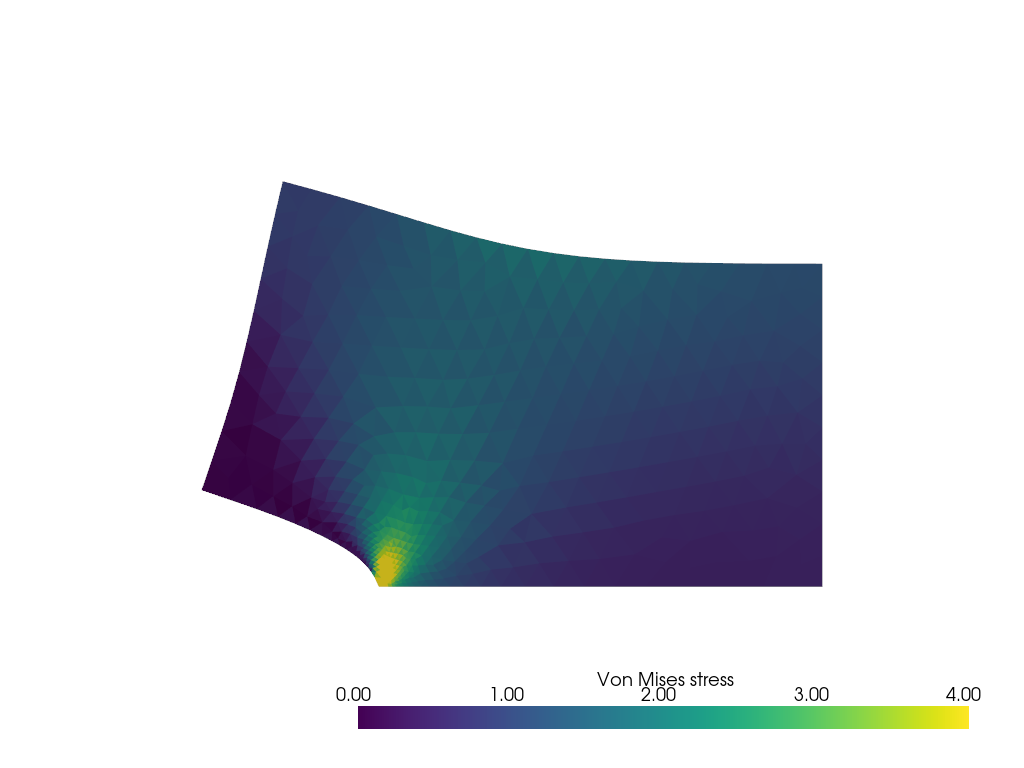

In [13]:
from plots import warp_plot_2d
plotter = warp_plot_2d(uh,cell_field=vm_stress,
                       field_name="Von Mises stress",
                       factor=0.1,
                       show_edges=False,
                       clim=[0, 4.0]
                       )

if not pyvista.OFF_SCREEN:
    plotter.show()

We can now wrap all the code in a the external module, so that we can resuse the solver later

We define in `elastic_solver.py` a function `solve_elasticity` taking as input  the crack length `Lcrack`, the geoemtric and mesh parameters, the Poisson ratio `nu`, and giving us as output the solution field `uh` and the related potential energy `energy`

The returned `uh` and `energy` will be calculated assuming a force density `f=1` on the top surface and a Young modulus `E=1`. This is without loss of generality, see the exercise below.


**Exercise.** 

Let be $u^{*}$ and $P^{*}$ the displacement field obtained on a domain $\Omega^*=[0,1]\times[0,\varrho]$ for a Young module $E^*=1$ and a load $f^*=1$ applied on the top surface. 
Determine by dimensional analysis the analytical formulas giving the 
displacement $u$ and the potential energy $P$ for any other value of  $E$,  load $f$, and for any domain $\Omega=[0,L]\times[0,\varrho\, L]$  obtained by a rescaling of $\Omega^*$ with a length-scale $L$.
Deduce that we can, without loss of generality, perform computation with $E=1$, $f=1$ and $L=1$.

In [14]:
from mpi4py import MPI
from elastic_solver import solve_elasticity

uh, energy, sigma_ufl = solve_elasticity(
    nu=0.3,
    E=1,
    load=1,
    Lx=1,
    Ly=0.5,
    Lcrack=0.3,
    lc=0.1,
    refinement_ratio=10,
    dist_min=0.2,
    dist_max=0.3,
    verbosity=1
)

with io.XDMFFile(MPI.COMM_WORLD, "output/elasticity-solver.xdmf", "w") as file:
    file.write_mesh(uh.function_space.mesh)
    file.write_function(uh)


The potential energy for Lcrack=3.000e-01 is -4.023e-01


## Fields along a line

The crack lies on $y=0$, from $x=0$ to $x=L_\mathrm{crack}$. Along that line
the vertical displacement is the half opening of the crack, and it vanishes
ahead of the tip, where the symmetry condition holds. The stress
$\sigma_{yy}$ does the opposite: it is zero on the free faces and unbounded
at the tip.

`evaluate_function`, from `utils/evaluation.py`, gives the values of a finite
element function at arbitrary points. It locates the points in the mesh,
evaluates there, and gathers the result across processes, so the same call
works in serial and in parallel.

In [15]:
from evaluation import evaluate_function

# sigma_yy as a finite element function, so that it can be evaluated at points.
# The displacement is P1, so the stress is constant over each cell. It is
# projected on P1 and not interpolated: interpolation would give each node the
# value of whichever neighbouring cell happened to be written last.
msh_solver = uh.function_space.mesh
dx_solver = ufl.Measure("dx", domain=msh_solver)
V_sigma = fem.functionspace(msh_solver, ("Lagrange", 1))
p, q = ufl.TrialFunction(V_sigma), ufl.TestFunction(V_sigma)
projection = fem.petsc.LinearProblem(
    ufl.inner(p, q) * dx_solver,
    ufl.inner(sigma_ufl[1, 1], q) * dx_solver,
    petsc_options_prefix="projection_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
)
sigma_yy = projection.solve()
sigma_yy.name = "sigma_yy"

# the points of the line y = 0, given as an array of shape (number of points, 2)
xs = np.linspace(0.0, Lx, 501)
points = np.zeros((xs.size, 2))
points[:, 0] = xs

u_y = evaluate_function(uh, points)[:, 1]
s_yy = evaluate_function(sigma_yy, points)[:, 0]

print(f"Half opening at the crack mouth: u_y(0,0) = {u_y[0]:.4f}")
print(f"Maximum sigma_yy on y=0: {s_yy.max():.4f} at x = {xs[s_yy.argmax()]:.3f}")

Half opening at the crack mouth: u_y(0,0) = 1.5920
Maximum sigma_yy on y=0: 11.8354 at x = 0.300


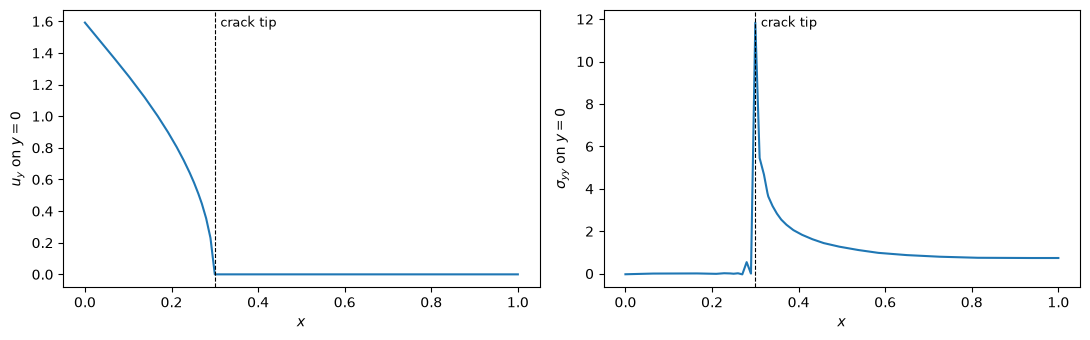

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].plot(xs, u_y)
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$u_y$ on $y=0$")

axes[1].plot(xs, s_yy)
axes[1].set_xlabel("$x$")
axes[1].set_ylabel(r"$\sigma_{yy}$ on $y=0$")

for ax in axes:
    ax.axvline(Lcrack, color="k", linestyle="--", linewidth=0.8)
    ax.annotate("crack tip", (Lcrack, ax.get_ylim()[1]), xytext=(4, -12),
                textcoords="offset points", fontsize=9)

fig.tight_layout()